# NPUWattch hands-on — 4. Timeloop: Gemmini-like vs. NVDLA-like

Two designs, two workloads, four runs. Both designs follow the
specifications in Table IV of the NPUWattch paper: int8 operands, int32
accumulation, LPDDR4 DRAM, 7 nm.

| | `gemmini_like` | `nvdla_like` |
| --- | --- | --- |
| Compute | 16×16 weight-stationary systolic array (256 MACs) | 8 MAC cells × 8 multipliers, adder-tree reduction (64 MACs) |
| On-chip buffer | 256 KB scratchpad + 64 KB accumulator | 64 KB CBUF + 1 KB CACC |
| Post-processing | none | SDP: bias, batch norm, ReLU, requantization |

The workloads are seven representative ResNet-50 layers and one Llama-3-8B
decoder block (prefill with 512 tokens, and decode of one token).


In [1]:
import sys; sys.path.insert(0, ".")
from tutorial_helpers import *
import pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
print("npuwattch:", npuwattch_binary())

npuwattch: /home/KNUEEhdd1/ys_knu/kmk/miniforge3/envs/npuwattch/bin/npuwattch


## 1. Run all four

Each run is a few seconds. We keep the headline numbers of each in one table.

In [2]:
runs = {
    "Gemmini / ResNet-50": example("timeloop/gemmini_like/resnet50"),
    "NVDLA / ResNet-50":   example("timeloop/nvdla_like/resnet50"),
    "Gemmini / Llama-3-8B": example("timeloop/gemmini_like/llama3_8b"),
    "NVDLA / Llama-3-8B":   example("timeloop/nvdla_like/llama3_8b"),
}
texts, rows = {}, []
for label, ex in runs.items():
    texts[label] = run(ex)
    rows.append(summary_row(report(ex), label))
summary = pd.DataFrame(rows)
display(summary.drop(columns="total_pJ"))

,design / workload,total energy,DRAM share %,area mm²,avg power,pJ / MAC
0,Gemmini / ResNet-50,1.06e+03 µJ,48.3,0.423,252 mW,1.99
1,NVDLA / ResNet-50,1.18e+03 µJ,60.0,0.088,88.3 mW,2.22
2,Gemmini / Llama-3-8B,2.52e+05 µJ,57.2,0.423,547 mW,2.21
3,NVDLA / Llama-3-8B,1.01e+06 µJ,90.5,0.088,565 mW,8.88


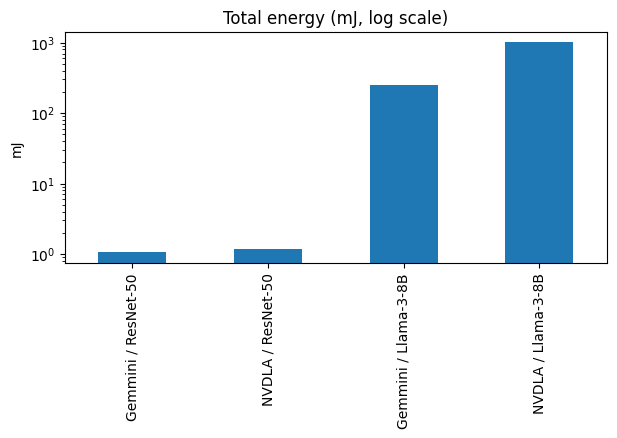

In [3]:
ax = summary.set_index("design / workload")["total_pJ"].div(1e9).plot.bar(figsize=(7, 3), legend=False, logy=True,
                                                                    title="Total energy (mJ, log scale)")
ax.set_xlabel(""); ax.set_ylabel("mJ");

## 2. Two taxes, and where the balance tips

Expected result (7 nm, 1 GHz, LPDDR4 at 8 pJ/bit):

| Design / workload | Total energy | DRAM bytes | Area |
| --- | --- | --- | --- |
| Gemmini-like / ResNet-50 | 1.06 mJ | 8.0 MB | 0.42 mm² |
| NVDLA-like / ResNet-50 | 1.18 mJ | 11.1 MB | 0.09 mm² |
| Gemmini-like / Llama-3-8B block | 252 mJ | 2.25 GB | 0.42 mm² |
| NVDLA-like / Llama-3-8B block | 1013 mJ | 14.3 GB | 0.09 mm² |

The two designs pay different taxes. The Gemmini-like design pays a
datapath tax: a register in every PE and a large accumulator SRAM. The
NVDLA-like design pays a buffer tax: its small buffers make the mapper fetch
more from DRAM. On ResNet-50 the two totals are within about 10% of each
other on this run. On the Llama-3-8B block the Gemmini-like run uses a
quarter of the energy of the NVDLA-like run; this holds for these two
configurations and this mapping rule, and section 2.2 shows which part of
the architecture files causes it.

### 2.1 ResNet-50: a datapath tax against a buffer tax

Start with the DRAM traffic. The DRAM bytes come from the Timeloop mapping:
they are a fact of the simulator run, not an output of an NPUWattch energy
model. The cell below sums the DRAM reads and writes of each run over the
stats files of all layers (one byte per int8 element) and multiplies them by
the LPDDR4 table value, 64 pJ per byte. The result is the DRAM row of each
report.

In [4]:
import re

def dram_bytes(example_dir):
    """DRAM reads and writes of a run in bytes, summed over the stats files of all layers.

    A DRAM word is one int8 element, so one scalar access is one byte.
    The writes are the 'Scalar updates' of the Outputs tensor at the DRAM level.
    """
    reads = writes = 0
    for path in sorted((example_dir / "stats").glob("*.stats.txt")):
        block = path.read_text().split("=== DRAM ===", 1)[1].split("\n=== ", 1)[0]
        reads += sum(int(x) for x in re.findall(r"Scalar reads \(per-instance\)\s*:\s*(\d+)", block))
        writes += sum(int(x) for x in re.findall(r"Scalar updates \(per-instance\)\s*:\s*(\d+)", block))
    return reads, writes

DRAM_PJ_PER_BYTE = 64          # LPDDR4, 8 pJ/bit: a table value, the same for both designs
traffic = []
for label, ex in runs.items():
    rep = report(ex)
    reads, writes = dram_bytes(ex)
    dram_row = next(c for c in rep["components"] if c["name"].endswith(".DRAM"))
    macs = rep["efficiency"]["mac_ops"]
    traffic.append({
        "design / workload": label,
        "DRAM reads": f"{reads / 1e6:,.1f} MB",
        "DRAM writes": f"{writes / 1e6:,.1f} MB",
        "DRAM bytes": f"{(reads + writes) / 1e6:,.1f} MB",
        "bytes x 64 pJ": f"{(reads + writes) * DRAM_PJ_PER_BYTE / 1e9:.4g} mJ",
        "DRAM row of the report": dram_row["energy_str"],
        "MACs": f"{macs:.3g}",
        "DRAM bytes / MAC": round((reads + writes) / macs, 4),
    })
display(pd.DataFrame(traffic))

,design / workload,DRAM reads,DRAM writes,DRAM bytes,bytes x 64 pJ,DRAM row of the report,MACs,DRAM bytes / MAC
0,Gemmini / ResNet-50,6.4 MB,1.5 MB,8.0 MB,0.5105 mJ,510 µJ,5.31e+08,0.0150
1,NVDLA / ResNet-50,9.5 MB,1.5 MB,11.1 MB,0.7084 mJ,708 µJ,5.31e+08,0.0208
2,Gemmini / Llama-3-8B,"2,218.8 MB",32.6 MB,"2,251.4 MB",144.1 mJ,1.44e+05 µJ,1.14e+11,0.0197
3,NVDLA / Llama-3-8B,"14,293.0 MB",32.6 MB,"14,325.5 MB",916.8 mJ,9.17e+05 µJ,1.14e+11,0.1256


In [5]:
reps = {k: report(v) for k, v in runs.items()}

def side_by_side(rep_a, rep_b, name_a, name_b, strip="system_top_level."):
    a = components_df(rep_a)[["component", "energy", "share %"]].assign(component=lambda d: d.component.str.replace(strip, "", regex=False))
    b = components_df(rep_b)[["component", "energy", "share %"]].assign(component=lambda d: d.component.str.replace(strip, "", regex=False))
    a.columns = ["component", f"{name_a} energy", f"{name_a} %"]
    b.columns = ["component", f"{name_b} energy", f"{name_b} %"]
    return pd.concat([a.set_index("component"), b.set_index("component")], axis=1).fillna("—")

display(side_by_side(reps["Gemmini / ResNet-50"], reps["NVDLA / ResNet-50"], "Gemmini", "NVDLA"))

,Gemmini energy,Gemmini %,NVDLA energy,NVDLA %
component,,,,
DRAM,510 µJ,48.3,708 µJ,60.0
gemmini.PE_column.PE.mac,377 µJ,35.7,—,—
gemmini.accumulator,87.5 µJ,8.3,—,—
gemmini.PE_column.PE.psum_reg,62.1 µJ,5.9,—,—
gemmini.scratchpad,11.9 µJ,1.1,—,—
gemmini.PE_column.PE.input_reg,3.89 µJ,0.4,—,—
gemmini.PE_column.PE.weight_reg,3.37 µJ,0.3,—,—
nvdla.mac_cell.lane.mac,—,—,376 µJ,31.9
nvdla.cacc,—,—,38.5 µJ,3.3


Both designs do the same 531 M int8 MACs, and the trained MAC model prices
them the same: 0.708 pJ each, 376 µJ in both reports. Everything else
differs.

**The architecture decides the DRAM traffic.** The NVDLA-like design has
64 KB of CBUF and 1 KB of CACC, against 256 KB plus 64 KB. Its buffers hold
less of a layer, so the mapper reads inputs and weights from DRAM more
often: 11.1 MB against 8.0 MB, about 1.4 times the bytes. The writes are the
same (1.5 MB of outputs), so the difference is all reads. The cost per byte
is a table value (LPDDR4, 8 pJ/bit), the same for both designs, so the DRAM
energy follows the bytes: 708 µJ against 510 µJ.

**The datapath tax of the Gemmini-like design.** A weight-stationary PE
keeps a partial sum in its own register and updates it on every MAC. With
clock gating, the update is one `psum_reg` write per MAC, 0.059 pJ, which is
8% of the 0.71 pJ MAC. (A read of a one-entry register costs 0 in the
characterization data.) That is the `psum_reg` row, 62 µJ or 5.9% of the
run. The 64 KB accumulator SRAM adds another 88 µJ (8.3%). The NVDLA-like
design reduces across its eight multipliers with an adder tree and writes
one partial sum per cell per cycle into a shared 1 KB CACC: no per-PE
register, and a cheaper accumulator (38 µJ). Its on-chip energy per MAC is
0.89 pJ against 1.03 pJ.

**The buffer tax of the NVDLA-like design.** The extra DRAM reads cost
198 µJ. Half of them are in the 1×1 expansion layer of res4, and most of the
rest in the 3×3 layers of res2 and res3 (per-window table below). The SDP
adds 24 µJ, 2% of the run, for the bias, batch norm, and ReLU that the
Gemmini-like design does not include.

**Where the balance tips.** The datapath saving of the NVDLA-like design is
about 110 µJ (the `psum_reg` and accumulator energy, minus its CACC). That
is less than its extra DRAM (198 µJ) plus the SDP (24 µJ), so on this run
the balance tips toward the Gemmini-like design by about 10%. This margin is inside
what a different SRAM or DRAM cost would move. At the HBM2 cost of
notebook 5 (3.48 pJ/bit), the extra DRAM would be 86 µJ, and the two totals
would be within 2% of each other. So the robust statement is about the
bytes: the NVDLA-like design moves 1.4 times the bytes on ResNet-50 and
7 times the bytes on the Llama-3-8B prefill layers. Whether its smaller
datapath pays back the extra bytes on ResNet-50 depends on the on-chip
costs, and the breakdown shows the balance
of this run.

In [6]:
def window_components(rep, label, top=8):
    labels = [w["label"] for w in rep["windows"]]
    j = labels.index(label)
    rows = [{"component": r["name"].replace("system_top_level.", ""), "energy": r["cells"][j]}
            for r in rep["matrix"]["rows"] if r["cells"][j] != "—"]
    return pd.DataFrame(rows).head(top)

display(window_components(reps["Gemmini / ResNet-50"], "03_res2_3x3"))
display(window_components(reps["NVDLA / ResNet-50"], "03_res2_3x3"))

,component,energy
0,DRAM,43.7 µJ
1,gemmini.scratchpad,963 nJ
2,gemmini.accumulator,9.53 µJ
3,gemmini.PE_column.PE.weight_reg,702 nJ
4,gemmini.PE_column.PE.input_reg,844 nJ
5,gemmini.PE_column.PE.psum_reg,13.5 µJ
6,gemmini.PE_column.PE.mac,81.9 µJ


,component,energy
0,DRAM,85.8 µJ
1,nvdla.sdp,3.14 µJ
2,nvdla.cbuf,4.59 µJ
3,nvdla.cacc,6.12 µJ
4,nvdla.mac_cell.lane.weight_reg,211 nJ
5,nvdla.mac_cell.lane.input_reg,1.69 µJ
6,nvdla.mac_cell.lane.mac,81.9 µJ


### 2.2 Llama-3-8B prefill: with no partial-sum spill, the accumulator size sets the DRAM traffic

The two architecture files of this tutorial share a mapping rule: neither
design may write a partial sum to memory and read it back. The constraints keep the
reduction loops innermost at the DRAM level, and keep output loops out of
the buffer above the accumulator (see the comments at the `DRAM` and `cbuf`
constraints in `timeloop/nvdla_like/arch.yaml`). So an output must stay in
the accumulator until its whole reduction is done. The FFN up-projection
reduces over K = 4096 for 512 × 28672 outputs. The Gemmini-like accumulator
holds 16 384 int32 outputs at a time; the NVDLA-like CACC, with the 1 KB of
the Table IV configuration, holds 256. For every group of outputs
that fits, the mapper streams the inputs and the weights of the full
reduction once more.

In [7]:
import re
display(window_components(reps["Gemmini / Llama-3-8B"], "prefill_6_ffn_up_gate"))
display(window_components(reps["NVDLA / Llama-3-8B"], "prefill_6_ffn_up_gate"))

def dram_reads_bytes(example_dir, layer):
    """DRAM scalar reads of a layer from its stats file (one entry per tensor)."""
    text = (example_dir / "stats" / f"{layer}.stats.txt").read_text()
    block = text.split("=== DRAM ===", 1)[1]
    return [int(x) for x in re.findall(r"Scalar reads \(per-instance\)\s*:\s*(\d+)", block)]

for label in ("Gemmini / Llama-3-8B", "NVDLA / Llama-3-8B"):
    reads = dram_reads_bytes(runs[label], "prefill_6_ffn_up_gate")
    print(f"{label:22s} DRAM reads per tensor: {reads}  total {sum(reads)/1e9:.2f} GB  "
          f"(weights are 117 MB, inputs 2 MB)")

,component,energy
0,DRAM,7.61e+04 µJ
1,gemmini.scratchpad,844 µJ
2,gemmini.accumulator,5.01e+03 µJ
3,gemmini.PE_column.PE.weight_reg,379 µJ
4,gemmini.PE_column.PE.input_reg,439 µJ
5,gemmini.PE_column.PE.psum_reg,7.1e+03 µJ
6,gemmini.PE_column.PE.mac,4.26e+04 µJ


,component,energy
0,DRAM,4.82e+05 µJ
1,nvdla.sdp,230 µJ
2,nvdla.cbuf,3.08e+03 µJ
3,nvdla.cacc,3.2e+03 µJ
4,nvdla.mac_cell.lane.weight_reg,54.9 µJ
5,nvdla.mac_cell.lane.input_reg,878 µJ
6,nvdla.mac_cell.lane.mac,4.26e+04 µJ


Gemmini / Llama-3-8B   DRAM reads per tensor: [939524096, 234881024, 0]  total 1.17 GB  (weights are 117 MB, inputs 2 MB)
NVDLA / Llama-3-8B     DRAM reads per tensor: [3758096384, 3758096384, 0]  total 7.52 GB  (weights are 117 MB, inputs 2 MB)


**Why the NVDLA-like design reads 7.5 GB for a 119 MB problem.** With 256
outputs per pass, the 512 × 28672 outputs need 57 344 passes, and each pass
streams a K = 4096 slice of inputs and weights. The stats show 3.76 GB of
weight reads (32 times the weight matrix) and 3.76 GB of input reads
(1800 times the 2 MB input). At 64 pJ per byte that is 482 mJ of DRAM for
this one layer, 90% of its energy. The Gemmini-like design, with 64 times
more accumulator, reads about 1.2 GB and spends 76 mJ. The MAC energy of the
two layers is identical (42.6 mJ).

**This comes from the configuration and the mapping rule.** Two things in
the architecture file of this tutorial produce the 7.5 GB: the 1 KB CACC of
the Table IV configuration, and the rule that no partial sum leaves the
accumulator. It is a property of this small configuration and of this
mapping rule, not of the NVDLA architecture in general. A configuration
with a larger accumulator, or a mapping that may write partial sums out and
read them back, reads far less from DRAM. The Gemmini-like result, with its
64 times larger accumulator, shows the direction.

**Why the cycle counts differ by four.** The NVDLA-like design has 64
multipliers against 256 PEs, so the same MACs take four times more cycles
(940 M against 235 M for this layer). More cycles means more leakage and, in
a real system, more DRAM refresh; at 7 nm both are small here.

### 2.3 Decode: the design does not matter

In decode every GEMM is a matrix-vector product: each weight is read from
DRAM once and used once. The DRAM energy of a layer is then fixed by its
weight bytes: `decode_6_ffn_up_gate` reads 117 MB of weights, 117 M × 64 pJ
= 7.5 mJ, on both designs.

In [8]:
pd.DataFrame([
    {"design": label.split(" / ")[0],
     "decode_6_ffn_up_gate": next(w["total_str"] for w in reps[label]["windows"] if w["label"] == "decode_6_ffn_up_gate"),
     "DRAM of that window": window_components(reps[label], "decode_6_ffn_up_gate", top=12).set_index("component").loc["DRAM", "energy"],
     "all 7 decode windows": f"{sum(w['total_pJ'] for w in reps[label]['windows'] if w['label'].startswith('decode')) / 1e9:.1f} mJ"}
    for label in ("Gemmini / Llama-3-8B", "NVDLA / Llama-3-8B")])

,design,decode_6_ffn_up_gate,DRAM of that window,all 7 decode windows
0,Gemmini,7.69e+03 µJ,7.52e+03 µJ,14.6 mJ
1,NVDLA,7.68e+03 µJ,7.55e+03 µJ,14.5 mJ


Both designs land at 7.7 mJ for the layer and about 15 mJ for the decode
step, with DRAM at 97 to 98%. The accumulator size, the PE registers, and
the array size are all irrelevant when there is no reuse to exploit; only
the bytes of the weights and the DRAM cost per bit remain. (Notebook 2 shows
the same floor on the TPU-like NPU with HBM2: 43.6 mJ for the fp32 block,
four times the bytes at a lower cost per bit.)

**What to look at.** For a CNN, look at the balance between the
accumulator access cost and the DRAM refetch: on this ResNet-50 run the two
designs are within about 10%, and these two terms set the difference. A
per-PE register costs little when it is clock-gated (0.06 pJ per MAC here,
8% of the MAC). For LLM prefill, with these two configurations and this
mapping rule, look at the accumulator capacity: the refetch factor is the
ratio of the reduction's outputs to the outputs the accumulator can hold.
For LLM decode, the accelerator design moves the energy very little on
these runs; the batch size and the data type are what move it. This holds at
the 512-token context of these runs. At tens of thousands of tokens the KV
reads of attention exceed the weight bytes, and the design matters again.

## 3. A block Timeloop never saw: the SDP

The NVDLA-like design has a post-processing unit (SDP) that handles bias,
batch norm, ReLU, and requantization. Timeloop has no model of it, so it does
not appear in the stats. NPUWattch charges it anyway, through two files in
`timeloop/nvdla_like/`.

In [9]:
print("--- user_components.yaml (the SDP entry) ---")
show_file(example("timeloop/nvdla_like/user_components.yaml"))
print()
print("--- stats_map.yaml ---")
show_file(example("timeloop/nvdla_like/stats_map.yaml"))

--- user_components.yaml (the SDP entry) ---
# ============================================================================
#  User component library of the NVDLA-like design
# ============================================================================
# A user component is a block that NPUWattch has no model for. You give its
# cost in this file: the area, and the energy of each action. NPUWattch does
# not calculate these values.
#
# This file is an INPUT of the run. NPUWattch reads `user_components.yaml`
# from the directory of the architecture file, or the file that you give with
# --user-components.
#
# This file has two entries:
#   nvdla_sdp               USED by arch.yaml (component `sdp`). Measured
#                           values, see below.
#   example_68000_cpu_core  AN EXAMPLE. No design uses it, thus each run shows
#                           the message NW-2116 ("... is in the library,
#                           but the run does not use it").
#
# How a design uses an

- `user_components.yaml` gives the SDP's area, leakage, and the energy of its
  two actions, measured at 7 nm. In `arch.yaml`, the `sdp` component carries
  the attribute `user_component: nvdla_sdp`, which points at this entry.
- `stats_map.yaml` gives it activity. Every DRAM write is one output element
  leaving the chip, and each element passes through the SDP once, so each
  DRAM write also charges one `process` action on the SDP. (The `count: 8`
  is because a DRAM write here is a 64-bit word that holds eight int8
  elements.)

In the component table the SDP shows up with `user` in the `model` column:

In [10]:
df = components_df(report(example("timeloop/nvdla_like/resnet50")))
display(df)
show_messages(texts["NVDLA / ResNet-50"], kinds=("INFO",))

,component,class,model,instances,energy,share %,area
0,system_top_level.DRAM,hbm,const,1,708 µJ,60.0,n/a
1,system_top_level.nvdla.mac_cell.lane.mac,intmac,cal,64,376 µJ,31.9,70.4
2,system_top_level.nvdla.cacc,sram,cal,1,38.5 µJ,3.3,1.14e+03
3,system_top_level.nvdla.cbuf,sram,cal,1,25.5 µJ,2.2,7.97e+04
4,system_top_level.nvdla.sdp,nvdla_sdp,user,1,24.1 µJ,2.0,1.94e+03
5,system_top_level.nvdla.mac_cell.lane.input_reg,regfile,cal,64,7.75 µJ,0.7,4.06
6,system_top_level.nvdla.mac_cell.lane.weight_reg,regfile,cal,64,694 nJ,0.1,4.06


INFO (NW-1026): Harness mode: timeloop
INFO (NW-1301): NPUWattch builds the description database from ../arch.yaml.
INFO (NW-1303): The description database has 7 components with 196 instances in total.
INFO (NW-1001): Instance hierarchy (declared in the Accelergy description):
INFO (NW-7403): system_top_level.DRAM (DRAM type LPDDR4): 8 pJ/bit from the shipped table lpddr4.yml.
INFO (NW-7301): system_top_level.DRAM (hbm): NPUWattch ignores the Accelergy attribute(s) datawidth.
INFO (NW-7109): system_top_level.nvdla.sdp: the user component library entry 'nvdla_sdp' gives the cost, not the class 'dummy_storage'.
INFO (NW-7306): system_top_level.nvdla.cbuf (sram): depth 8192 is the total of 16 banks, so mem_depth_per_bank is 512 (64 KB total).
INFO (NW-7307): system_top_level.nvdla.cbuf (sram): no port count is declared, so NPUWattch uses one shared read-write port.
INFO (NW-7308): system_top_level.nvdla.cbuf (sram): bandwidth 16 words/cycle (8 words per access) gives up to 2 bank accesse

The SDP is about 2% of the ResNet-50 energy and well under 1% of the Llama
energy. Small, but now it is in the breakdown instead of missing from it.

The INFO line `NW-7222`, `Stats level 'DRAM' charges more than one
component: ...`, confirms what the stats map did.

## Messages you will see

**Every time.** The same INFO lines as in notebook 3 (`NW-7307`, `NW-2116`,
`NW-7101`, and `NW-3107`, the clock-gating line of every run), plus, for the
NVDLA-like design, two INFO lines: `NW-7109` for the `user_component`
attribute and `NW-7222` for the stats-map fan-out. No WARNING lines.

**If something looks wrong.** The table at the end of notebook 3 applies here
too. One more case for designs with a user component:

| What you see | What it means | What to do |
| --- | --- | --- |
| `WARNING (NW-8302): ...: User component 'X': the values are for 7nm, but the run is at 5nm.` | Your entry was measured at another node than the run | State the node your numbers belong to in `reference:`; NPUWattch uses them as given and tells you about the difference. We are preparing to support scaling user components across nodes in a future release. |

Next: `05_your_own_data.ipynb`.